# LASSO vs. Linear Regression (OLS)

**Question:** using only the original inputs (no squares, interactions, or made-up columns), does a tuned LASSO predict better than ordinary least squares?

- **Part I:** Student Performance (math course): predict the final grade `G3`.
- **Part II:** Residential Building data (UCI): predict a building's sale price.

Both parts use **the same testing procedure**, written once as functions below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score
from sklearn.base import BaseEstimator, RegressorMixin

warnings.filterwarnings("ignore")   # hide convergence chatter from LassoCV
pd.set_option("display.precision", 4)

N_SPLITS = 50      # number of random train/test splits
TEST_SIZE = 0.25   # 25% of rows held out for testing in each split
CV_FOLDS = 5       # folds used to tune lambda inside the training set


class OLS(BaseEstimator, RegressorMixin):
    """Ordinary least squares, solved with a fixed numerical cutoff.

    Identical to LinearRegression when the inputs are linearly independent.
    When some inputs are exact combinations of others (true in Part II), there
    are infinitely many least-squares solutions. This always returns the standard
    one (the minimum-norm solution) instead of whatever a given computer's math
    library happens to return: directions with singular value below
    1e-10 x the largest are treated as exactly zero.
    """
    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        self.x_mean_, self.y_mean_ = X.mean(axis=0), y.mean()
        self.coef_ = np.linalg.lstsq(X - self.x_mean_, y - self.y_mean_, rcond=1e-10)[0]
        self.intercept_ = self.y_mean_ - self.x_mean_ @ self.coef_
        return self

    def predict(self, X):
        return np.asarray(X, float) @ self.coef_ + self.intercept_

## The testing procedure (shared by Part I and Part II)

For each of **50 random splits** (seeds 0–49):

1. Split the rows **75% train / 25% test**.
2. **OLS:** standardize the inputs, then fit ordinary linear regression on the training rows.
3. **LASSO:** standardize the inputs, then pick the penalty $\lambda$ (called `alpha` in scikit-learn) with **5-fold cross-validation on the training rows only**, trying 100 values of $\lambda$. The model is refit on all training rows with the best $\lambda$.
4. Score both models on the **test rows** with $R^2$ (the share of variance in the target the model explains on data it never saw).

**Why this design:**
- **Test $R^2$ on held-out data** measures prediction, which is the question. Training $R^2$ always favors OLS, because OLS minimizes training error by definition.
- **50 splits instead of one:** a single split can be lucky or unlucky. With 50 we see the whole spread and can count how often each model wins.
- **$\lambda$ is tuned only inside the training set,** so the test rows never influence model choice. Otherwise LASSO would get an unfair peek at the test data.
- **Both models see the same split each time,** so the comparison is paired: split by split.
- **Standardizing** puts every input on the same scale. The LASSO penalty treats all coefficients equally, so this matters. It also makes the coefficients comparable in Section 4.

**What counts as a win** (from the assignment): LASSO must have the higher **median** test $R^2$ *and* beat OLS on **more than half** of the 50 splits.

In [2]:
def compare_models(X, y):
    """Run OLS and tuned LASSO on N_SPLITS random splits and return test R^2 for each."""
    rows = []
    for seed in range(N_SPLITS):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=seed)

        ols = make_pipeline(StandardScaler(), OLS()).fit(X_tr, y_tr)
        lasso = make_pipeline(StandardScaler(),
                              LassoCV(cv=CV_FOLDS, random_state=seed, max_iter=50000)).fit(X_tr, y_tr)

        lasso_coefs = lasso[-1].coef_
        rows.append({
            "split": seed,
            "OLS_R2": r2_score(y_te, ols.predict(X_te)),
            "LASSO_R2": r2_score(y_te, lasso.predict(X_te)),
            "lambda": lasso[-1].alpha_,
            "n_vars_kept": int((lasso_coefs != 0).sum()),
            "kept": lasso_coefs != 0,
        })
    res = pd.DataFrame(rows)
    res["LASSO_minus_OLS"] = res["LASSO_R2"] - res["OLS_R2"]
    return res


def summary_table(res):
    """Summarize test R^2 over all splits for both models."""
    tab = pd.DataFrame({
        "OLS": res["OLS_R2"].describe(percentiles=[.25, .5, .75]),
        "LASSO": res["LASSO_R2"].describe(percentiles=[.25, .5, .75]),
    }).drop("count")
    tab.index = ["mean", "std", "min", "25%", "median", "75%", "max"]
    wins = int((res["LASSO_R2"] > res["OLS_R2"]).sum())
    print(f"LASSO beats OLS on {wins} of {len(res)} splits ({wins/len(res):.0%})")
    print(f"Median test R^2:  OLS = {res['OLS_R2'].median():.4f}   LASSO = {res['LASSO_R2'].median():.4f}")
    print(f"Median lambda chosen = {res['lambda'].median():.4g};  "
          f"median # inputs kept by LASSO = {res['n_vars_kept'].median():.0f} of {len(res['kept'][0])}")
    print("LASSO works by the assignment's rule:",
          res["LASSO_R2"].median() > res["OLS_R2"].median() and wins > len(res) / 2)
    return tab


def plot_results(res, title):
    """Left: distribution of test R^2. Right: split-by-split comparison."""
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].boxplot([res["OLS_R2"], res["LASSO_R2"]], labels=["OLS", "LASSO"])
    ax[0].set_ylabel("Test $R^2$")
    ax[0].set_title("Test $R^2$ over 50 splits")

    lo = min(res["OLS_R2"].min(), res["LASSO_R2"].min())
    hi = max(res["OLS_R2"].max(), res["LASSO_R2"].max())
    win = res["LASSO_R2"] > res["OLS_R2"]
    ax[1].scatter(res.loc[win, "OLS_R2"], res.loc[win, "LASSO_R2"], label="LASSO better")
    ax[1].scatter(res.loc[~win, "OLS_R2"], res.loc[~win, "LASSO_R2"], marker="x", label="OLS better")
    ax[1].plot([lo, hi], [lo, hi], "k--", lw=1, label="tie line")
    ax[1].set_xlabel("OLS test $R^2$")
    ax[1].set_ylabel("LASSO test $R^2$")
    ax[1].set_title("Each dot = one split (above the line = LASSO wins)")
    ax[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def coefficient_table(X, y, res):
    """Fit both models on all rows (standardized) and compare coefficients."""
    ols = make_pipeline(StandardScaler(), OLS()).fit(X, y)
    lasso = make_pipeline(StandardScaler(), LassoCV(cv=CV_FOLDS, random_state=0, max_iter=50000)).fit(X, y)
    coefs = pd.DataFrame({
        "OLS_coef": ols[-1].coef_,
        "LASSO_coef": lasso[-1].coef_,
        "kept_by_LASSO_in_%_of_splits": 100 * np.vstack(res["kept"]).mean(axis=0),
    }, index=X.columns)
    coefs["shrinkage"] = coefs["LASSO_coef"].abs() - coefs["OLS_coef"].abs()
    coefs = coefs.reindex(coefs["OLS_coef"].abs().sort_values(ascending=False).index)
    n_kept = int((coefs["LASSO_coef"] != 0).sum())
    print(f"Full-data fit: OLS uses all {len(coefs)} inputs; LASSO (lambda = {lasso[-1].alpha_:.4g}) keeps {n_kept}.")
    print(f"Sum of |coefficients|:  OLS = {coefs['OLS_coef'].abs().sum():.2f}   LASSO = {coefs['LASSO_coef'].abs().sum():.2f}")
    return coefs

# Part I: Student Performance (math)

## 1. Introduce the dataset

In [3]:
students = pd.read_csv("Data/student_performance.csv")
print("Shape:", students.shape)
students.head()

Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Missing values: 0
Students with G3 = 0: 38
Of those, G2 = 0 too: 13

Correlation of G3 with G1 and G2:
G1    0.801
G2    0.905
G3    1.000
Name: G3, dtype: float64


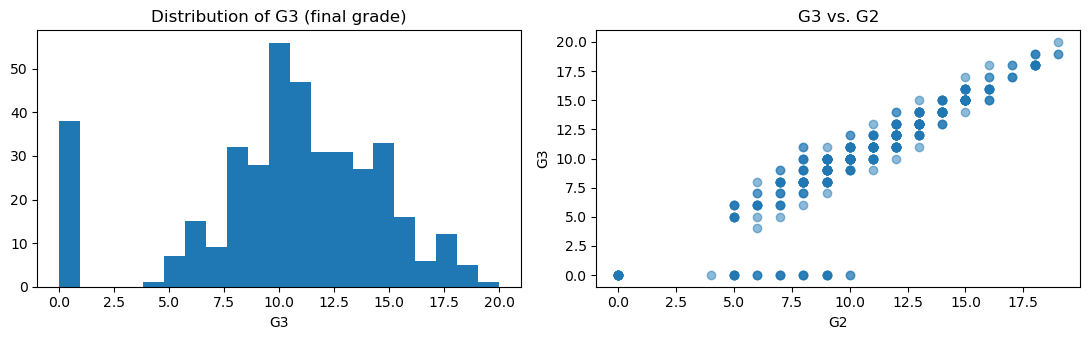

In [4]:
print("Missing values:", students.isna().sum().sum())
print("Students with G3 = 0:", (students["G3"] == 0).sum())
print("Of those, G2 = 0 too:", ((students["G3"] == 0) & (students["G2"] == 0)).sum())
print("\nCorrelation of G3 with G1 and G2:")
print(students[["G1", "G2", "G3"]].corr()["G3"].round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(students["G3"], bins=21)
ax[0].set_title("Distribution of G3 (final grade)")
ax[0].set_xlabel("G3")
ax[1].scatter(students["G2"], students["G3"], alpha=.5)
ax[1].set_title("G3 vs. G2")
ax[1].set_xlabel("G2")
ax[1].set_ylabel("G3")
plt.tight_layout()
plt.show()

In [5]:
# Inputs: everything except G3. Yes/no and text columns become 0/1 dummy columns
# (drop_first avoids a redundant column per category). No squares or interactions.
y1 = students["G3"]
X1 = pd.get_dummies(students.drop(columns="G3"), drop_first=True).astype(float)
print("Rows:", X1.shape[0], "  Input columns after dummy coding:", X1.shape[1])

Rows: 395   Input columns after dummy coding: 41


**About the data**
- **A row** is one student in a math course at one of two Portuguese secondary schools (GP or MS): **395 students, 33 columns**.
- **Target:** `G3`, the final grade (0â€“20).
- **Inputs:** the other 32 columns: earlier grades `G1`, `G2`, plus demographics, family, school-support and lifestyle variables. After turning the yes/no and text columns into 0/1 dummies there are **41 input columns**.

**Things that are unusual**
- **38 students have `G3 = 0`.** These look like students who dropped out or skipped the final exam, not students who really scored zero. 13 of them also have `G2 = 0`. These zeros are hard for any linear model to predict.
- **`G2` is almost the answer:** its correlation with `G3` is **0.905** (`G1`: 0.801). A few inputs carry nearly all of the signal, and most of the other ~39 probably add little. That is the setting where LASSO can help.
- No missing values.

## 2. Testing procedure

Same procedure as described above: **50 random 75/25 splits**, so each split trains on 296 students and tests on 99. $\lambda$ is tuned by **5-fold CV inside the training set**, and both models are scored by **test $R^2$**.

## 3. OLS vs. tuned LASSO over 50 splits

In [6]:
res1 = compare_models(X1, y1)
summary_table(res1)

LASSO beats OLS on 43 of 50 splits (86%)
Median test R^2:  OLS = 0.7977   LASSO = 0.8127
Median lambda chosen = 0.1505;  median # inputs kept by LASSO = 10 of 41
LASSO works by the assignment's rule: True


,OLS,LASSO
mean,0.7940,0.8176
std,0.0405,0.0434
min,0.7142,0.7101
25%,0.7571,0.7902
median,0.7977,0.8127
75%,0.8193,0.8505
max,0.8859,0.9068


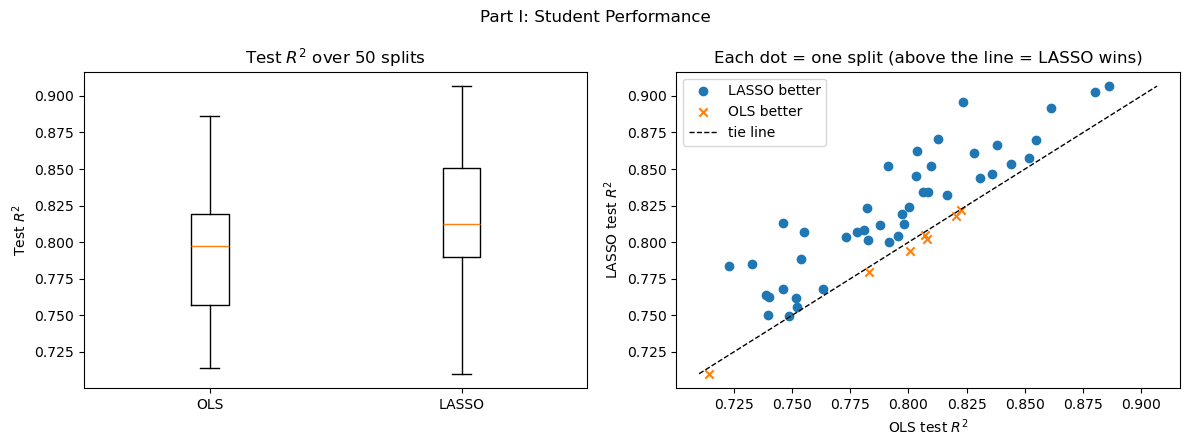

In [7]:
plot_results(res1, "Part I: Student Performance")

In [8]:
# The first 10 splits, to show the paired comparison
res1[["split", "OLS_R2", "LASSO_R2", "LASSO_minus_OLS", "lambda", "n_vars_kept"]].head(10)

,split,OLS_R2,LASSO_R2,LASSO_minus_OLS,lambda,n_vars_kept
0,0,0.7829,0.7794,-0.0036,0.1201,12
1,1,0.7463,0.7684,0.0220,0.1622,11
2,2,0.8279,0.8609,0.0330,0.1827,8
3,3,0.8360,0.8464,0.0104,0.2025,4
4,4,0.8516,0.8577,0.0061,0.1866,8
5,5,0.7398,0.7504,0.0106,0.1450,8
6,6,0.7827,0.8015,0.0188,0.1462,9
7,7,0.8097,0.8524,0.0427,0.1058,18
8,8,0.8305,0.8442,0.0137,0.3080,2
9,9,0.8233,0.8958,0.0725,0.1825,10


**Result: LASSO wins.**
- **Median test $R^2$:** LASSO **0.8127** vs. OLS **0.7977** (+0.015).
- **LASSO beats OLS on 43 of 50 splits (86%).** Both conditions of the assignment's rule hold.
- The scatter plot shows almost every dot above the tie line. The boxplot shows LASSO's whole middle 50% (0.790â€“0.851) sitting higher than OLS's (0.757â€“0.819).
- LASSO is not better on *every* split. It lost 7 times, for example split 0 (0.7794 vs. 0.7829), and its single worst split (0.7101) is slightly below OLS's worst (0.7142).

## 4. Summary of the variables

In [9]:
coefs1 = coefficient_table(X1, y1, res1)
coefs1

Full-data fit: OLS uses all 41 inputs; LASSO (lambda = 0.1559) keeps 8.
Sum of |coefficients|:  OLS = 8.07   LASSO = 4.46


,OLS_coef,LASSO_coef,kept_by_LASSO_in_%_of_splits,shrinkage
G2,3.5964,3.6137,100.0,0.0173
G1,0.6260,0.4124,100.0,-0.2136
absences,0.3667,0.1510,96.0,-0.2157
famrel,0.3196,0.1433,92.0,-0.1763
Walc,0.2274,0.0000,28.0,-0.2274
age,-0.2209,-0.0574,74.0,-0.1634
activities_yes,-0.1730,-0.0000,50.0,-0.1730
Dalc,-0.1646,0.0000,0.0,-0.1646
school_MS,0.1542,0.0000,8.0,-0.1542
schoolsup_yes,0.1531,0.0000,32.0,-0.1531


**Which variables each model uses**
- **OLS uses all 41 inputs.** It gives every one a non-zero coefficient, even ones that are pure noise.
- **LASSO keeps only 8 inputs** on the full data (median of 10 across the 50 splits). The core ones it keeps in almost every split:
  - `G2` (100% of splits), `G1` (100%), `absences` (96%), `famrel` (92%), then `age` (74%) and `failures` (64%).
- Variables like `Dalc`, `Fedu` and `address_U` are **never** kept (0% of splits), even though OLS gives them coefficients around Â±0.15.

**How the coefficients compare** (standardized, so they are in "grade points per 1 SD of the input")
- `G2` is almost unchanged (OLS 3.60 â†’ LASSO 3.61). LASSO trusts the strong signal.
- The weaker real signals are **shrunk**: `G1` 0.63 â†’ 0.41, `absences` 0.37 â†’ 0.15, `famrel` 0.32 â†’ 0.14.
- Most of the rest go to **exactly zero**. The total size of the coefficients (sum of |coef|) drops from **8.07 (OLS) to 4.46 (LASSO)**.

## 5. Why LASSO works better here

In [10]:
d = res1["LASSO_minus_OLS"]
print(f"Average gain of LASSO over OLS: {d.mean():.4f}   median gain: {d.median():.4f}")
print(f"Spread (std) of test R^2:  OLS = {res1['OLS_R2'].std():.4f}   LASSO = {res1['LASSO_R2'].std():.4f}")
print(f"Worst split:  OLS = {res1['OLS_R2'].min():.4f}   LASSO = {res1['LASSO_R2'].min():.4f}")

Average gain of LASSO over OLS: 0.0236   median gain: 0.0223
Spread (std) of test R^2:  OLS = 0.0405   LASSO = 0.0434
Worst split:  OLS = 0.7142   LASSO = 0.7101


**Why LASSO predicts better here**

1. **Most inputs add little.** `G2` alone has correlation 0.905 with `G3`. LASSO keeps a median of only **10 of 41** inputs, and many variables are kept in under 10% of splits. That means the cross-validation itself found that adding them hurts out-of-sample prediction.
2. **OLS fits noise in those extra inputs.** With 296 training rows and 41 coefficients, OLS gives small but non-zero weights to things like `Dalc` (âˆ’0.16) and `Fedu` (âˆ’0.15). Those weights describe *this* training sample, not students in general, so they add error on new students.
3. **LASSO removes that noise.** Setting weak coefficients to zero and shrinking the rest trades a little bias for much less variance. The net effect on new data is an average gain of **+0.024 in test $R^2$** (median +0.022), and a win on **43 of 50 splits**.

**Honest caveat:** the gain is real but modest, and LASSO's results are not more stable here: their spread (std 0.043) is about the same as OLS (0.041). The ~38 zero grades limit both models.

# Part II: Residential Building data

## 1. Introduce the dataset

In [11]:
# Downloaded from https://archive.ics.uci.edu/dataset/437/residential+building+data+set
# The first row of the sheet holds group labels, so the real column names are in row 2 (header=1).
build = pd.read_excel("Data/residential_building.xlsx", header=1)
print("Shape:", build.shape)
build.iloc[:5, :12]

Shape: (372, 109)


,START YEAR,START QUARTER,COMPLETION YEAR,COMPLETION QUARTER,V-1,V-2,V-3,V-4,V-5,V-6,V-7,V-8
0,81,1,85,1,1,3150.0,920.0,598.5,190,1010.84,16,1200
1,84,1,89,4,1,7600.0,1140.0,3040.0,400,963.81,23,2900
2,78,1,81,4,1,4800.0,840.0,480.0,100,689.84,15,630
3,72,2,73,2,1,685.0,202.0,13.7,20,459.54,4,140
4,87,1,90,2,1,3000.0,800.0,1230.0,410,631.91,13,5000


In [12]:
print("Missing values:", build.isna().sum().sum())
print("\nTarget V-9 (actual sales price, 10,000 IRR):")
print(build["V-9"].describe().round(1))

# Many inputs are the same economic indicator measured at different lags (e.g. V-11, V-11.1, ..., V-11.4)
corr = build.drop(columns=["V-9", "V-10"]).corr().abs().values
upper = corr[np.triu_indices_from(corr, k=1)]
print(f"\nPairs of inputs with |correlation| > 0.9: {(upper > 0.9).sum()} of {len(upper)}")

# Stronger: some inputs are EXACT linear combinations of others
Z = StandardScaler().fit_transform(build.drop(columns=["V-9", "V-10"]))
print(f"Rank of the input matrix: {np.linalg.matrix_rank(Z)} of {Z.shape[1]} columns")
quarters = ((build["COMPLETION YEAR"] * 4 + build["COMPLETION QUARTER"])
            - (build["START YEAR"] * 4 + build["START QUARTER"]))
print("Example: V-7 (duration) equals the quarters from start to completion in",
      f"{(quarters == build['V-7']).mean():.0%} of rows")

Missing values: 0

Target V-9 (actual sales price, 10,000 IRR):
count     372.0
mean     1387.4
std      1206.1
min        50.0
25%       577.5
50%      1000.0
75%      1700.0
max      6800.0
Name: V-9, dtype: float64

Pairs of inputs with |correlation| > 0.9: 1287 of 5671
Rank of the input matrix: 75 of 107 columns
Example: V-7 (duration) equals the quarters from start to completion in 100% of rows


In [13]:
# Target = V-9 (sales price). V-10 (construction cost) is the dataset's *other* target,
# not an input, so it is dropped. All 107 remaining columns are original inputs.
y2 = build["V-9"]
X2 = build.drop(columns=["V-9", "V-10"])
print("Rows:", X2.shape[0], "  Inputs:", X2.shape[1])

Rows: 372   Inputs: 107


**About the data**
- **Source:** Residential Building Data Set, UCI Machine Learning Repository (Rafiei & Adeli, 2016): <https://archive.ics.uci.edu/dataset/437/residential+building+data+set>. It is free to download.
- **A row** is one residential apartment building project in Tehran, Iran: **372 buildings**.
- **Target:** `V-9`, the **actual sale price** (in units of 10,000 Iranian rials).
- **Inputs (107 columns, all original):**
  - Project timing: `START YEAR`, `START QUARTER`, `COMPLETION YEAR`, `COMPLETION QUARTER`.
  - 8 physical/financial project variables `V-1` to `V-8` (e.g. locality, floor area, lot area, preliminary cost estimates, construction duration, `V-8` = price per unit at the start of the project).
  - 19 economic indicators (`V-11` to `V-29`), each recorded at **5 time lags** (`V-11`, `V-11.1`, â€¦, `V-11.4`). That gives 95 columns.

**Things that are unusual**
- The spreadsheet has **two header rows**. Row 1 is group labels, so we read it with `header=1`.
- It has **two targets**: `V-9` (sale price) and `V-10` (construction cost). We predict `V-9` and **drop `V-10`**, because it is an outcome, not an input.
- **Very many inputs for the number of rows:** 107 inputs and 372 rows (only ~2.6 training rows per input).
- **Extreme collinearity:** the lagged economic indicators move together. **1,287 pairs of inputs have |correlation| > 0.9.**
- **Some inputs are exact copies of combinations of others:** the 107 input columns have **rank 75**, so 32 columns add no new information at all. For example, `V-7` (construction duration) equals the number of quarters from start to completion in 100% of rows.
  - Because of this, OLS has infinitely many "best" solutions. The `OLS` class in the setup cell always returns the standard (minimum-norm) one. With plain `LinearRegression`, the result depended on the computer: on one machine OLS gave sensible answers, and on another it produced coefficients near $10^{15}$ and a median test $R^2$ around $-10^{19}$.
- No missing values.

**Datasets ruled out:** none. Following the tip (many inputs relative to rows), this was the first dataset we tried, and it met the rule on the first run.

## 2. Testing procedure

Same procedure as Part I, with the same functions: **50 random 75/25 splits** (279 train / 93 test buildings), **5-fold CV inside the training set** to tune $\lambda$, scored by **test $R^2$**.
Here there are only about 2.6 training rows per input (279 / 107), so OLS has very little data per coefficient.

## 3. OLS vs. tuned LASSO over 50 splits

In [14]:
res2 = compare_models(X2, y2)
summary_table(res2)

LASSO beats OLS on 45 of 50 splits (90%)
Median test R^2:  OLS = 0.9721   LASSO = 0.9781
Median lambda chosen = 3.085;  median # inputs kept by LASSO = 26 of 107
LASSO works by the assignment's rule: True


,OLS,LASSO
mean,0.9693,0.9764
std,0.0111,0.0074
min,0.9391,0.9529
25%,0.9645,0.9728
median,0.9721,0.9781
75%,0.9770,0.9809
max,0.9857,0.9871


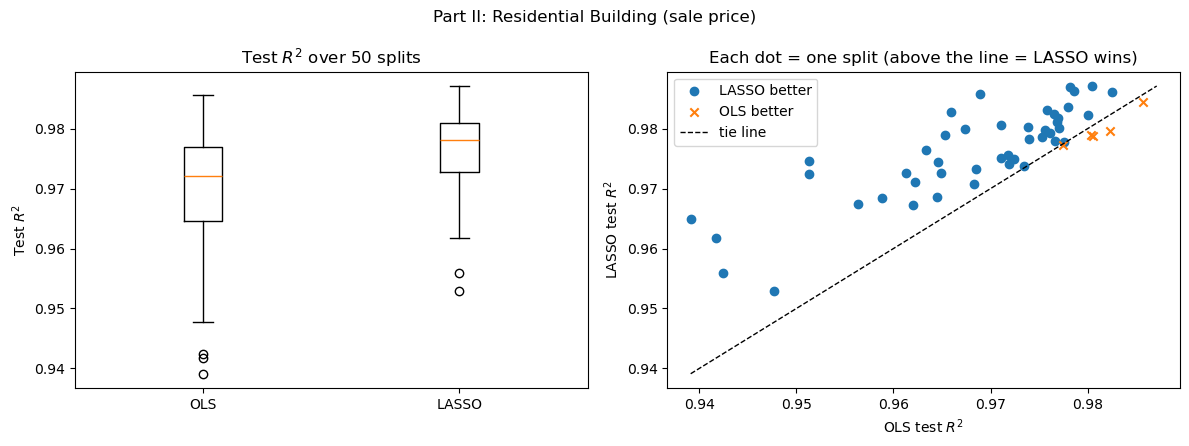

In [15]:
plot_results(res2, "Part II: Residential Building (sale price)")

In [16]:
res2[["split", "OLS_R2", "LASSO_R2", "LASSO_minus_OLS", "lambda", "n_vars_kept"]].head(10)

,split,OLS_R2,LASSO_R2,LASSO_minus_OLS,lambda,n_vars_kept
0,0,0.9724,0.9750,0.0026,1.1844,33
1,1,0.9477,0.9529,0.0052,1.3416,32
2,2,0.9710,0.9807,0.0097,1.1325,34
3,3,0.9857,0.9845,-0.0012,5.3526,24
4,4,0.9806,0.9788,-0.0018,3.9023,22
5,5,0.9762,0.9793,0.0031,1.1725,30
6,6,0.9801,0.9822,0.0021,1.9924,29
7,7,0.9753,0.9786,0.0033,3.8710,27
8,8,0.9391,0.9649,0.0258,1.2265,33
9,9,0.9770,0.9801,0.0030,5.3253,20


**Result: LASSO wins.**
- **Median test $R^2$:** LASSO **0.9781** vs. OLS **0.9721**.
- **LASSO beats OLS on 45 of 50 splits (90%).** Both conditions of the rule hold.
- Both models score high, because the price per unit at the start (`V-8`) predicts the final price very well. The difference shows up in the **bad splits**: OLS's worst split is **0.9391**, LASSO's is **0.9529** (see split 8: 0.9391 vs. 0.9649).
- The boxplot shows LASSO's box is both higher and **tighter**: std **0.0074** vs. **0.0111** for OLS.

## 4. Summary of the variables

In [17]:
coefs2 = coefficient_table(X2, y2, res2)
coefs2.head(25)

Full-data fit: OLS uses all 107 inputs; LASSO (lambda = 1.667) keeps 32.
Sum of |coefficients|:  OLS = 16162.16   LASSO = 2388.01


,OLS_coef,LASSO_coef,kept_by_LASSO_in_%_of_splits,shrinkage
V-8,1196.6258,1173.7741,100.0,-22.8517
V-27.3,-562.8220,-0.0000,0.0,-562.8220
V-17.2,553.6080,-0.0000,0.0,-553.6080
V-22.4,-506.5807,0.0000,2.0,-506.5807
V-17.3,-452.8055,-397.4254,98.0,-55.3801
V-29,-447.4681,40.9546,38.0,-406.5134
V-21.4,434.1764,0.0000,16.0,-434.1764
START QUARTER,382.3029,-0.0000,12.0,-382.3029
V-16.3,-381.7804,-0.0000,72.0,-381.7804
V-21.3,346.5395,0.0000,0.0,-346.5395


In [18]:
# Variables LASSO keeps in the full-data fit, largest first
coefs2[coefs2["LASSO_coef"] != 0].sort_values("LASSO_coef", key=abs, ascending=False)

,OLS_coef,LASSO_coef,kept_by_LASSO_in_%_of_splits,shrinkage
V-8,1196.6258,1173.7741,100.0,-22.8517
V-17.3,-452.8055,-397.4254,98.0,-55.3801
V-27.1,269.2678,113.7229,100.0,-155.5450
V-19.3,45.6040,84.4980,100.0,38.8940
V-19.2,173.8492,83.1670,100.0,-90.6822
V-19,179.1528,79.7798,98.0,-99.3730
V-7,86.4491,75.6661,100.0,-10.7830
V-2,119.3430,59.8518,70.0,-59.4912
V-3,-114.0591,-53.6897,76.0,-60.3695
V-29,-447.4681,40.9546,38.0,-406.5134


**Which variables each model uses**
- **OLS uses all 107 inputs.**
- **LASSO keeps 32** on the full data (median **26** across the 50 splits).
- Inputs LASSO keeps in essentially every split: `V-8` (price per unit at start), `V-7` (construction duration), `V-1` (locality), `V-17.3`, `V-27.1`, the `V-19` lags, and `COMPLETION QUARTER`.
- From most groups of 5 lagged economic indicators, LASSO keeps **one or two lags and drops the rest.** Groups like `V-21`, `V-25` and `V-26` are dropped almost completely.

**How the coefficients compare**
- The main driver is nearly identical in both: `V-8` is **1197 (OLS) vs. 1174 (LASSO)**.
- After that, OLS's coefficients are **huge and unstable**. For example, `V-27.3` = âˆ’563 and `V-17.2` = +554, `V-22.4` = âˆ’507, `V-21.4` = +434. **LASSO sets all four to exactly 0**, and keeps them in 0â€“16% of splits.
- Some OLS coefficients even have the **opposite sign** from LASSO (e.g. `V-29`: OLS âˆ’447, LASSO +41). That is a classic sign of collinear inputs canceling each other out.
- Total coefficient size: sum of |coef| **16,162 (OLS) vs. 2,388 (LASSO)**, about 7 times smaller.

## 5. Why LASSO works better here

In [19]:
d = res2["LASSO_minus_OLS"]
print(f"Average gain of LASSO over OLS: {d.mean():.4f}   median gain: {d.median():.4f}")
print(f"Spread (std) of test R^2:  OLS = {res2['OLS_R2'].std():.4f}   LASSO = {res2['LASSO_R2'].std():.4f}")
print(f"Worst split:  OLS = {res2['OLS_R2'].min():.4f}   LASSO = {res2['LASSO_R2'].min():.4f}")

Average gain of LASSO over OLS: 0.0071   median gain: 0.0052
Spread (std) of test R^2:  OLS = 0.0111   LASSO = 0.0074
Worst split:  OLS = 0.9391   LASSO = 0.9529


**Why LASSO predicts better here**

1. **Too many inputs for the rows.** OLS must estimate 108 numbers (107 slopes + intercept) from 279 training buildings. Each coefficient is estimated from very little information, so its variance is high.
2. **The inputs are highly redundant.** Only **75 of the 107** columns carry independent information. With **1,287 pairs correlated above 0.9**, OLS can't tell lagged copies of the same indicator apart. It gives them large coefficients of opposite sign that cancel on the training data (e.g. `V-27.3` âˆ’563, `V-17.2` +554). On new buildings the cancelation is not exact, and the error grows.
3. **LASSO picks one from each redundant group and zeroes the rest.** It keeps a median of **26 of 107** inputs and cuts total coefficient size **from 16,162 to 2,388**. The leftover model is simpler and much less sensitive to which buildings were in the training set.
4. **The evidence:**
   - LASSO wins **45 of 50** splits.
   - Its median $R^2$ is higher: **0.9781 vs. 0.9721**.
   - It is **more stable**: std 0.0074 vs. 0.0111.
   - It helps most when OLS does badly: worst split **0.9529 vs. 0.9391**.

This dataset matches the tip almost exactly: many inputs relative to rows, and many of them (the extra lags) add little new information.

# Conclusion

| | Part I: Student Performance | Part II: Residential Building |
|---|---|---|
| Rows / inputs | 395 / 41 | 372 / 107 |
| Median test $R^2$ OLS | 0.7977 | 0.9721 |
| Median test $R^2$ LASSO | **0.8127** | **0.9781** |
| LASSO wins (of 50) | **43** | **45** |
| Inputs LASSO keeps (median) | 10 | 26 |
| LASSO works by the rule? | Yes | Yes |

In both datasets, LASSO wins by **dropping inputs that add noise and shrinking the rest**. The gain is largest in stability when inputs are many and redundant (Part II).

# AI use statement

I used **Claude (Claude Code, Anthropic)** to help plan the testing procedure, write the Python code, suggest and download a Part II dataset that fit the "many inputs, few rows" tip, and draft the explanations. I checked every number in the text against the notebook output.

Things that needed fixing or checking:
- The Residential Building spreadsheet has two header rows. Reading it normally gives the wrong column names, so it has to be read with `header=1`.
- The dataset has two target columns (`V-9` sale price, `V-10` construction cost). Leaving `V-10` in as an input would be using one outcome to predict another, so it had to be dropped.
- **The AI's first version used scikit-learn's `LinearRegression` for OLS.** On my own computer (Anaconda) that gave a median OLS test $R^2$ of about $-10^{19}$ in Part II. On the AI's run it gave 0.97. The cause is that 32 of the 107 inputs are exact linear combinations of others (rank 75), so the answer depended on each computer's math library. I replaced it with an `OLS` class that always returns the standard minimum-norm solution, and added the rank check to Section 1.